# Pull Air Classifier — Event-Level MLB
Binary classifier predicting whether a contact event results in a pulled air ball.

**Features:** swing metrics, contact depth, pitch location  
**Models:** Logistic Regression (baseline) + XGBoost  
**Evaluation:** AUC, calibration, feature importance  
**Class imbalance:** handled via class weighting / scale_pos_weight


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    classification_report, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import joblib

pd.set_option("display.float_format", "{:.4f}".format)

TARGET    = "pull_air"
CV_FOLDS  = 5
SEED      = 42
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

print("Imports OK")


Imports OK


## 2. Load & Engineer Features

In [2]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))
raw_all  = pd.concat([raw_2024, raw_2025], ignore_index=True)

# ── Contact filter
contact = raw_all[
    raw_all["launch_speed"].notna() &
    raw_all["launch_angle"].notna() &
    raw_all["hc_x"].notna() &
    raw_all["hc_y"].notna() &
    raw_all["stand"].notna() &
    raw_all["bat_speed"].notna() &
    raw_all["swing_path_tilt"].notna() &
    raw_all["attack_angle"].notna() &
    raw_all["attack_direction"].notna() &
    raw_all["plate_x"].notna() &
    raw_all["plate_z"].notna() &
    raw_all["sz_top"].notna() &
    raw_all["sz_bot"].notna() &
    raw_all["batter"].notna()
].copy().reset_index(drop=True)

print(f"Contact events with full tracking: {len(contact):,}")

# ── Target
contact["spray_angle_norm"] = np.where(
    contact["stand"] == "R",
    np.degrees(np.arctan((contact["hc_x"] - 125.42) / (198.27 - contact["hc_y"]))),
    -np.degrees(np.arctan((contact["hc_x"] - 125.42) / (198.27 - contact["hc_y"]))),
)
contact[TARGET] = (
    (contact["spray_angle_norm"] > 0) & (contact["launch_angle"] >= 10)
).astype(int)

print(f"\nClass distribution:")
vc = contact[TARGET].value_counts()
print(f"  Not pull air (0): {vc[0]:,}  ({vc[0]/len(contact)*100:.1f}%)")
print(f"  Pull air     (1): {vc[1]:,}  ({vc[1]/len(contact)*100:.1f}%)")

# ── Attack direction normalised
contact["attack_direction_norm"] = np.where(
    contact["stand"] == "R",
    contact["attack_direction"],
    -contact["attack_direction"],
)

# ── Plate location relative to batter (pull-side = negative)
contact["plate_x_norm"] = np.where(
    contact["stand"] == "R",
    contact["plate_x"],
    -contact["plate_x"],
)

# ── Plate z relative to strike zone midpoint
contact["sz_mid"]      = (contact["sz_top"] + contact["sz_bot"]) / 2
contact["plate_z_rel"] = contact["plate_z"] - contact["sz_mid"]

# ── VAA
Y0, Y_PLATE = 50.0, 17 / 12
t_plate = (
    (-contact["vy0"] - np.sqrt(
        contact["vy0"]**2 - 4 * (0.5 * contact["ay"]) * (Y0 - Y_PLATE)
    )) / (2 * 0.5 * contact["ay"])
)
contact["vaa"] = np.degrees(np.arctan(
    (contact["vz0"] + contact["az"] * t_plate) /
    (contact["vy0"] + contact["ay"] * t_plate).abs()
))

# ── Contact depth bin (p90 from 2024+2025)
depth_col = "intercept_ball_minus_batter_pos_y_inches"
if depth_col in contact.columns:
    p90 = contact[depth_col].quantile(0.90)
    contact["contact_depth_bin"] = pd.cut(
        contact[depth_col].fillna(contact[depth_col].median()),
        bins=[-np.inf, p90, np.inf],
        labels=[0, 1],
    ).astype(float)
    print(f"\nContact depth p90: {p90:.2f} inches")
else:
    contact["contact_depth_bin"] = 0.0
    print("⚠  contact depth column not found")

# ── Pitch bucket encoding
PITCH_BUCKETS = {
    "FF":0,"FA":0,"SI":0,"FT":0,"FC":0,
    "SL":1,"ST":1,"SV":1,"CU":1,"KC":1,"CS":1,
    "CH":2,"FS":2,"FO":2,"EP":2,"KN":2,
}
contact["pitch_bucket_enc"] = contact["pitch_type"].map(PITCH_BUCKETS).fillna(-1).astype(int)

# ── Count
contact["is_2_strikes"]    = (contact["strikes"] == 2).astype(int)
contact["is_hitter_count"] = (
    ((contact["balls"] == 2) & (contact["strikes"] == 0)) |
    ((contact["balls"] == 3) & (contact["strikes"] <= 1))
).astype(int)

print(f"\nEngineering complete.")


Contact events with full tracking: 231,856

Class distribution:
  Not pull air (0): 163,734  (70.6%)
  Pull air     (1): 68,122  (29.4%)

Contact depth p90: 40.02 inches

Engineering complete.


## 3. Feature Set

In [3]:
SWING_FEATURES = [
    "bat_speed",
    "swing_path_tilt",
    "attack_angle",
    "attack_direction_norm",
]

DEPTH_FEATURES = [
    "contact_depth_bin",
]

LOCATION_FEATURES = [
    "plate_x_norm",
    "plate_z_rel",
    "release_speed",
]

COUNT_FEATURES = [
    "is_2_strikes",
    "is_hitter_count",
]

CAT_FEATURES = [
    "pitch_bucket_enc",
]

ALL_FEATURES = (SWING_FEATURES + DEPTH_FEATURES +
                LOCATION_FEATURES + COUNT_FEATURES + CAT_FEATURES)

print(f"Total features: {len(ALL_FEATURES)}")
print(ALL_FEATURES)

# ── Build model dataframe
df_model = contact[ALL_FEATURES + [TARGET]].dropna().reset_index(drop=True)
print(f"\nModel rows: {len(df_model):,}  (dropped {len(contact) - len(df_model):,})")

X = df_model[ALL_FEATURES].values
y = df_model[TARGET].values

# Class imbalance ratio for XGBoost
neg, pos  = (y == 0).sum(), (y == 1).sum()
scale_pos = neg / pos
print(f"\nscale_pos_weight for XGBoost: {scale_pos:.3f}")


Total features: 11
['bat_speed', 'swing_path_tilt', 'attack_angle', 'attack_direction_norm', 'contact_depth_bin', 'plate_x_norm', 'plate_z_rel', 'release_speed', 'is_2_strikes', 'is_hitter_count', 'pitch_bucket_enc']

Model rows: 231,856  (dropped 0)

scale_pos_weight for XGBoost: 2.404


## 4. Train / Validation Split

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Train: {len(X_train):,}  Val: {len(X_val):,}")
print(f"Train pull air rate: {y_train.mean():.3f}")
print(f"Val   pull air rate: {y_val.mean():.3f}")


Train: 185,484  Val: 46,372
Train pull air rate: 0.294
Val   pull air rate: 0.294


## 5. Logistic Regression (Baseline)

In [5]:
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr",     LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED,
        C=0.1,
    )),
])

# CV AUC
cv      = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
lr_aucs = cross_val_score(lr_pipe, X_train, y_train, cv=cv,
                           scoring="roc_auc", n_jobs=-1)
lr_aps  = cross_val_score(lr_pipe, X_train, y_train, cv=cv,
                           scoring="average_precision", n_jobs=-1)

print(f"Logistic Regression ({CV_FOLDS}-fold CV):")
print(f"  ROC-AUC : {lr_aucs.mean():.4f} ± {lr_aucs.std():.4f}")
print(f"  Avg Prec: {lr_aps.mean():.4f} ± {lr_aps.std():.4f}")

# Fit on full train, eval on val
lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_val)[:, 1]

print(f"\nVal ROC-AUC : {roc_auc_score(y_val, lr_probs):.4f}")
print(f"Val Avg Prec: {average_precision_score(y_val, lr_probs):.4f}")
print(f"Val Brier   : {brier_score_loss(y_val, lr_probs):.4f}")


Logistic Regression (5-fold CV):
  ROC-AUC : 0.6652 ± 0.0015
  Avg Prec: 0.4106 ± 0.0025

Val ROC-AUC : 0.6705
Val Avg Prec: 0.4161
Val Brier   : 0.2301


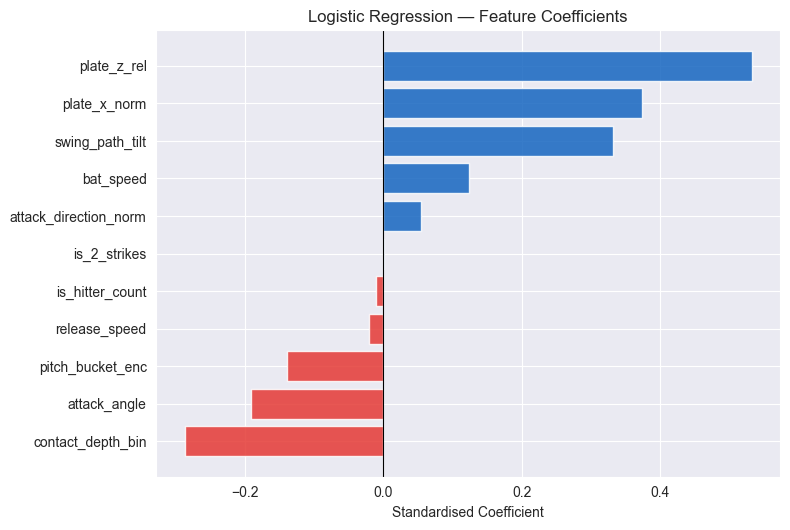

In [6]:
# ── Logistic regression coefficients
scaler_lr = lr_pipe.named_steps["scaler"]
lr_model  = lr_pipe.named_steps["lr"]
coefs     = lr_model.coef_[0]

coef_df = (
    pd.DataFrame({"Feature": ALL_FEATURES, "Coef": coefs})
    .sort_values("Coef")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(ALL_FEATURES) + 1))
colors = ["#E53935" if c < 0 else "#1565C0" for c in coef_df["Coef"]]
ax.barh(coef_df["Feature"], coef_df["Coef"], color=colors, alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardised Coefficient")
ax.set_title("Logistic Regression — Feature Coefficients")
plt.tight_layout()
plt.show()


## 6. XGBoost

In [7]:
xgb_model = XGBClassifier(
    n_estimators          = 800,
    learning_rate         = 0.04,
    max_depth             = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 20,
    reg_lambda            = 2.0,
    scale_pos_weight      = scale_pos,
    eval_metric           = "auc",
    early_stopping_rounds = 40,
    random_state          = SEED,
    verbosity             = 0,
    device                = "cpu",
)

# CV AUC (no early stopping in CV — use fixed n_estimators from a proxy fit)
xgb_cv = XGBClassifier(
    n_estimators     = 400,
    learning_rate    = 0.04,
    max_depth        = 5,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    min_child_weight = 20,
    reg_lambda       = 2.0,
    scale_pos_weight = scale_pos,
    random_state     = SEED,
    verbosity        = 0,
    device           = "cpu",
)
xgb_aucs = cross_val_score(xgb_cv, X_train, y_train, cv=cv,
                            scoring="roc_auc", n_jobs=1)
xgb_aps  = cross_val_score(xgb_cv, X_train, y_train, cv=cv,
                            scoring="average_precision", n_jobs=1)

print(f"XGBoost ({CV_FOLDS}-fold CV):")
print(f"  ROC-AUC : {xgb_aucs.mean():.4f} ± {xgb_aucs.std():.4f}")
print(f"  Avg Prec: {xgb_aps.mean():.4f} ± {xgb_aps.std():.4f}")

# Fit with early stopping on held-out val
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
xgb_probs = xgb_model.predict_proba(X_val)[:, 1]

print(f"\nVal ROC-AUC : {roc_auc_score(y_val, xgb_probs):.4f}")
print(f"Val Avg Prec: {average_precision_score(y_val, xgb_probs):.4f}")
print(f"Val Brier   : {brier_score_loss(y_val, xgb_probs):.4f}")
print(f"Best iteration: {xgb_model.best_iteration}")


XGBoost (5-fold CV):
  ROC-AUC : 0.7252 ± 0.0018
  Avg Prec: 0.5029 ± 0.0041

Val ROC-AUC : 0.7302
Val Avg Prec: 0.5117
Val Brier   : 0.2109
Best iteration: 538


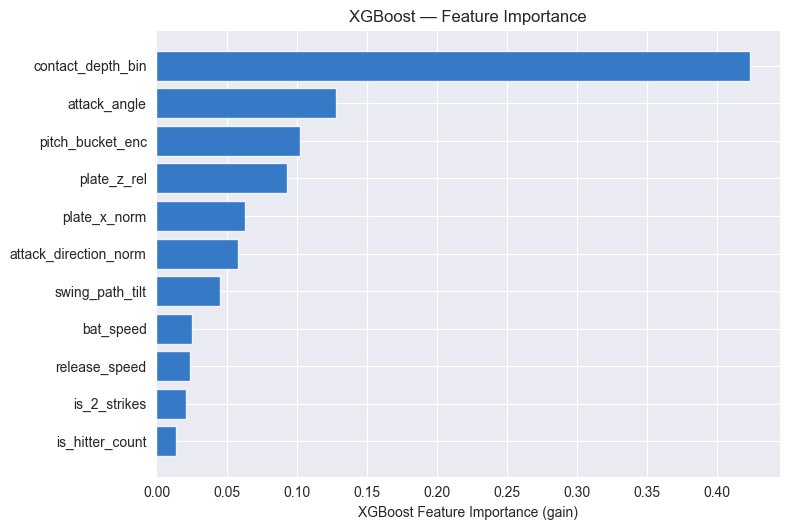

In [8]:
# ── XGBoost feature importance
imp_df = (
    pd.DataFrame({
        "Feature":    ALL_FEATURES,
        "Importance": xgb_model.feature_importances_,
    })
    .sort_values("Importance")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(ALL_FEATURES) + 1))
ax.barh(imp_df["Feature"], imp_df["Importance"],
        color="#1565C0", alpha=0.85)
ax.set_xlabel("XGBoost Feature Importance (gain)")
ax.set_title("XGBoost — Feature Importance")
plt.tight_layout()
plt.show()


## 7. Model Comparison — ROC & PR Curves

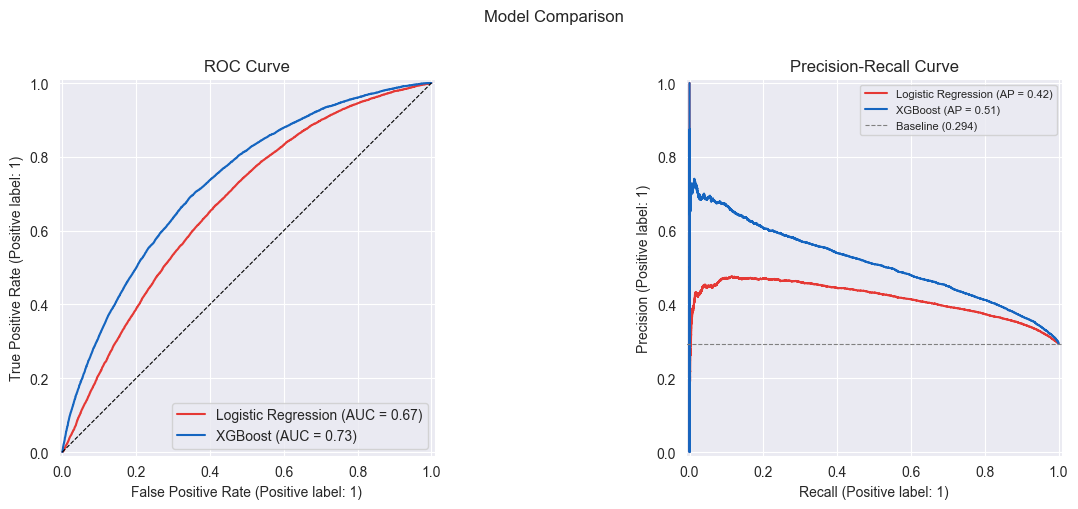

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC
RocCurveDisplay.from_predictions(
    y_val, lr_probs, name="Logistic Regression", ax=axes[0], color="#E53935"
)
RocCurveDisplay.from_predictions(
    y_val, xgb_probs, name="XGBoost", ax=axes[0], color="#1565C0"
)
axes[0].plot([0,1],[0,1],"k--",linewidth=0.8)
axes[0].set_title("ROC Curve")

# Precision-Recall
PrecisionRecallDisplay.from_predictions(
    y_val, lr_probs, name="Logistic Regression", ax=axes[1], color="#E53935"
)
PrecisionRecallDisplay.from_predictions(
    y_val, xgb_probs, name="XGBoost", ax=axes[1], color="#1565C0"
)
axes[1].axhline(y_val.mean(), color="gray", linestyle="--",
                linewidth=0.8, label=f"Baseline ({y_val.mean():.3f})")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(fontsize=8)

plt.suptitle("Model Comparison", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()


## 8. Calibration

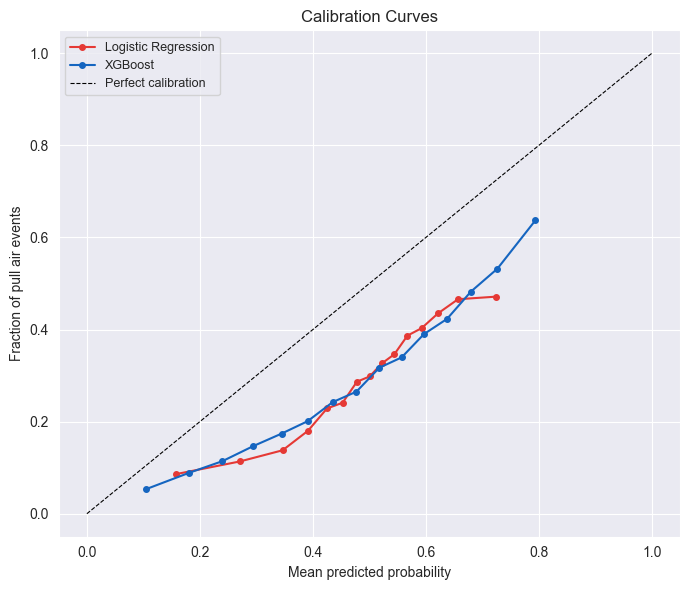

Brier scores (lower = better):
  Logistic Regression : 0.2301
  XGBoost             : 0.2109
  Baseline (always predict base rate): 0.2075


In [10]:
fig, ax = plt.subplots(figsize=(7, 6))

for probs, label, color in [
    (lr_probs,  "Logistic Regression", "#E53935"),
    (xgb_probs, "XGBoost",            "#1565C0"),
]:
    frac_pos, mean_pred = calibration_curve(y_val, probs, n_bins=15,
                                             strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", markersize=4,
            color=color, linewidth=1.5, label=label)

ax.plot([0,1],[0,1],"k--",linewidth=0.8, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of pull air events")
ax.set_title("Calibration Curves")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Brier score summary
print("Brier scores (lower = better):")
print(f"  Logistic Regression : {brier_score_loss(y_val, lr_probs):.4f}")
print(f"  XGBoost             : {brier_score_loss(y_val, xgb_probs):.4f}")
print(f"  Baseline (always predict base rate): "
      f"{brier_score_loss(y_val, np.full_like(y_val, y_val.mean(), dtype=float)):.4f}")


## 9. Calibrate XGBoost with Isotonic Regression
XGBoost with scale_pos_weight can produce poorly calibrated probabilities.
Isotonic regression post-calibration fixes this without affecting ranking.


Post-calibration Brier: 0.1790
Post-calibration AUC  : 0.7311


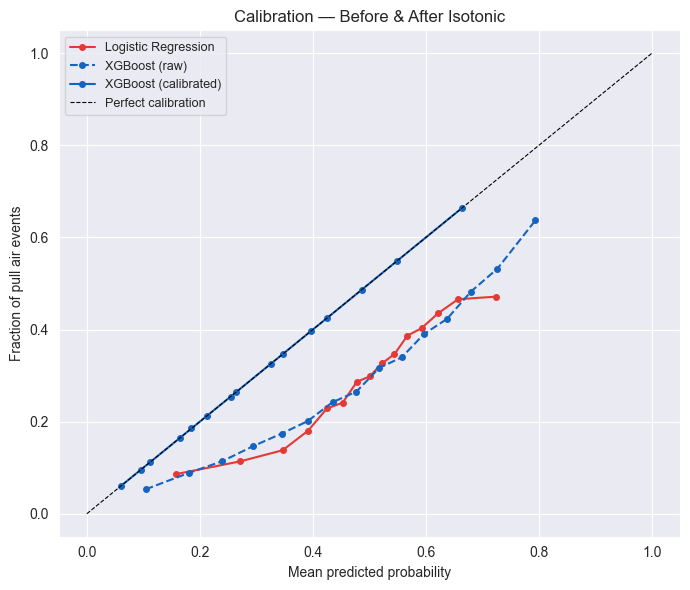

In [11]:
# Fit isotonic calibration on val set
from sklearn.isotonic import IsotonicRegression

iso_cal = IsotonicRegression(out_of_bounds="clip")
iso_cal.fit(xgb_probs, y_val)
xgb_probs_cal = iso_cal.predict(xgb_probs)

print(f"Post-calibration Brier: {brier_score_loss(y_val, xgb_probs_cal):.4f}")
print(f"Post-calibration AUC  : {roc_auc_score(y_val, xgb_probs_cal):.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
for probs, label, color, ls in [
    (lr_probs,      "Logistic Regression",   "#E53935", "-"),
    (xgb_probs,     "XGBoost (raw)",         "#1565C0", "--"),
    (xgb_probs_cal, "XGBoost (calibrated)",  "#1565C0", "-"),
]:
    frac_pos, mean_pred = calibration_curve(y_val, probs, n_bins=15,
                                             strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", markersize=4,
            color=color, linewidth=1.5, linestyle=ls, label=label)

ax.plot([0,1],[0,1],"k--",linewidth=0.8, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of pull air events")
ax.set_title("Calibration — Before & After Isotonic")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 10. Save Artifacts

In [12]:
# Save XGBoost + calibrator + feature list
xgb_model.save_model(str(MODEL_DIR / "pull_air_xgb.json"))
joblib.dump(iso_cal,      MODEL_DIR / "pull_air_isotonic.pkl")
joblib.dump(lr_pipe,      MODEL_DIR / "pull_air_lr.pkl")

meta = {
    "all_features":    ALL_FEATURES,
    "target":          TARGET,
    "val_auc":         float(roc_auc_score(y_val, xgb_probs)),
    "val_auc_cal":     float(roc_auc_score(y_val, xgb_probs_cal)),
    "val_brier":       float(brier_score_loss(y_val, xgb_probs)),
    "val_brier_cal":   float(brier_score_loss(y_val, xgb_probs_cal)),
    "base_rate":       float(y.mean()),
    "scale_pos_weight":float(scale_pos),
    "depth_p90":       float(p90) if "p90" in dir() else None,
}
joblib.dump(meta, MODEL_DIR / "pull_air_meta.pkl")

print("Saved:")
print("  models/pull_air_xgb.json")
print("  models/pull_air_isotonic.pkl")
print("  models/pull_air_lr.pkl")
print("  models/pull_air_meta.pkl")
print(f"\nFinal model summary:")
print(f"  Base rate          : {meta['base_rate']:.3f}")
print(f"  Val AUC (raw)      : {meta['val_auc']:.4f}")
print(f"  Val AUC (cal)      : {meta['val_auc_cal']:.4f}")
print(f"  Val Brier (raw)    : {meta['val_brier']:.4f}")
print(f"  Val Brier (cal)    : {meta['val_brier_cal']:.4f}")


Saved:
  models/pull_air_xgb.json
  models/pull_air_isotonic.pkl
  models/pull_air_lr.pkl
  models/pull_air_meta.pkl

Final model summary:
  Base rate          : 0.294
  Val AUC (raw)      : 0.7302
  Val AUC (cal)      : 0.7311
  Val Brier (raw)    : 0.2109
  Val Brier (cal)    : 0.1790


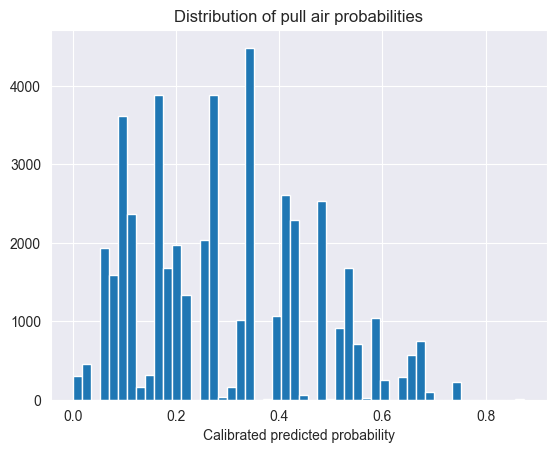

High confidence predictions: 6,557
Accuracy when p > 0.5: 0.582


In [13]:
# Probability distribution of predictions
plt.hist(xgb_probs_cal, bins=50)
plt.xlabel("Calibrated predicted probability")
plt.title("Distribution of pull air probabilities")
plt.show()

# High-confidence prediction accuracy
high_conf = xgb_probs_cal > 0.5
print(f"High confidence predictions: {high_conf.sum():,}")
print(f"Accuracy when p > 0.5: {(y_val[high_conf] == 1).mean():.3f}")

Platt AUC  : 0.7306
Platt Brier: 0.1793


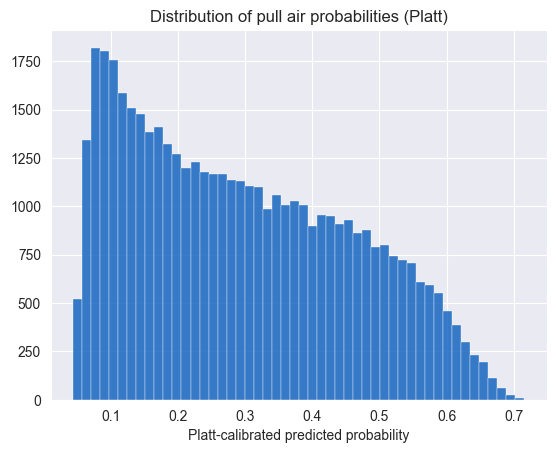

In [14]:
from sklearn.calibration import CalibratedClassifierCV

# Refit calibration using sigmoid (Platt scaling)
# Need a fresh uncalibrated model to wrap
xgb_for_cal = XGBClassifier(
    n_estimators     = xgb_model.best_iteration,
    learning_rate    = 0.04,
    max_depth        = 5,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    min_child_weight = 20,
    reg_lambda       = 2.0,
    scale_pos_weight = scale_pos,
    random_state     = SEED,
    verbosity        = 0,
    device           = "cpu",
)

platt_cal = CalibratedClassifierCV(xgb_for_cal, method="sigmoid", cv=5)
platt_cal.fit(X_train, y_train)
xgb_probs_platt = platt_cal.predict_proba(X_val)[:, 1]

print(f"Platt AUC  : {roc_auc_score(y_val, xgb_probs_platt):.4f}")
print(f"Platt Brier: {brier_score_loss(y_val, xgb_probs_platt):.4f}")

plt.hist(xgb_probs_platt, bins=50, color="#1565C0", alpha=0.85,
         edgecolor="white", linewidth=0.3)
plt.xlabel("Platt-calibrated predicted probability")
plt.title("Distribution of pull air probabilities (Platt)")
plt.show()

Qualified batters : 675
Pearson r         : 0.2673  (p=1.67e-12)
Spearman ρ        : 0.2561  (p=1.45e-11)


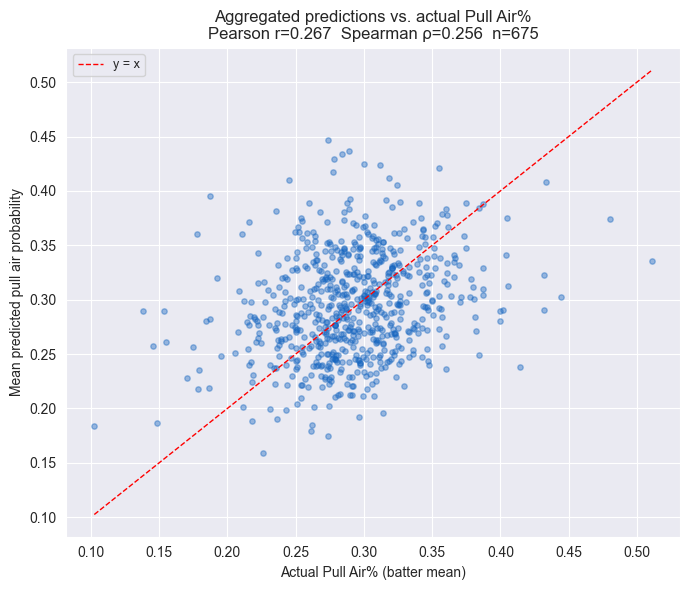

In [19]:
from scipy.stats import pearsonr, spearmanr

# ── Aggregate predicted pull air probability to batter level ──────────────────
probs_all = platt_cal.predict_proba(X)[:, 1]

df_model_pred = df_model.copy()
df_model_pred["pred_prob"] = probs_all
df_model_pred["batter"]    = contact.loc[df_model.index, "batter"].values

batter_agg = (
    df_model_pred.groupby("batter")
    .agg(
        n               = ("pull_air",  "count"),
        actual_pull_air = ("pull_air",  "mean"),
        mean_pred_prob  = ("pred_prob", "mean"),
    )
    .query("n >= 25")
    .reset_index()
)

r_p, p_p = pearsonr(batter_agg["actual_pull_air"], batter_agg["mean_pred_prob"])
r_s, p_s = spearmanr(batter_agg["actual_pull_air"], batter_agg["mean_pred_prob"])

print(f"Qualified batters : {len(batter_agg)}")
print(f"Pearson r         : {r_p:.4f}  (p={p_p:.2e})")
print(f"Spearman ρ        : {r_s:.4f}  (p={p_s:.2e})")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(batter_agg["actual_pull_air"], batter_agg["mean_pred_prob"],
           alpha=0.4, s=15, color="#1565C0")
lims = [
    min(batter_agg["actual_pull_air"].min(), batter_agg["mean_pred_prob"].min()),
    max(batter_agg["actual_pull_air"].max(), batter_agg["mean_pred_prob"].max()),
]
ax.plot(lims, lims, "r--", linewidth=1, label="y = x")
ax.set_xlabel("Actual Pull Air% (batter mean)")
ax.set_ylabel("Mean predicted pull air probability")
ax.set_title(f"Aggregated predictions vs. actual Pull Air%\n"
             f"Pearson r={r_p:.3f}  Spearman ρ={r_s:.3f}  n={len(batter_agg)}")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()